# M4c — Métricas do modelo no conjunto de teste holdout

Agora que o holdout tem gabarito de verdade (gerado pelo notebook 07 e alinhado pelo notebook 09), este notebook mede precision/recall/F1 do modelo (treinado no notebook 06) sobre esse conjunto — documentos genuinamente novos, fora do treino e da validação usados no notebook 06, diferente da avaliação interna que o próprio notebook 06 já faz sobre seu split de teste.

Reaproveita a mesma lógica de diagnóstico que existia no antigo notebook `07.investigar_erros_bertimbau.ipynb` (matriz de confusão a nível de token, classificação de cada erro por categoria, amostras para leitura manual, ranking de documentos, CSV de erro completo, comparação antes/depois do pós-processamento heurístico e visualização com TP/FN/FP sobrepostos) — agora aplicada ao holdout real.

**Pré-requisitos:** notebooks 07 (ground truth), 08 (extração OCR) e 09 (alinhamento) já rodados para o holdout; notebook 06 já treinou o modelo.

**Depois deste notebook:** `notebooks/11.verificar_resultados_manualmente.ipynb`, para inspeção visual página a página.

In [1]:
import json
import random
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from transformers import AutoModelForTokenClassification, AutoTokenizer

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

print(f"CUDA disponível: {torch.cuda.is_available()}")

d:\Arquivos\ProjetosPython\BFC\LocalScanDocument_v3\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CUDA disponível: True


## Configuração

`MODELO_GABARITO` deve bater com o que foi usado no notebook 09 (alinhamento). `INCLUIR_SINTETICOS`/`CENARIO_MANUAL` escolhem o experimento/cenário treinado, igual notebook 06.

In [2]:
def encontrar_raiz_projeto(marcador: str = "requirements.txt") -> Path:
    p = Path.cwd()
    for _ in range(6):
        if (p / marcador).exists():
            return p
        p = p.parent
    raise RuntimeError(f"Não encontrei a raiz do projeto ({marcador}) subindo a partir de {Path.cwd()}")

RAIZ = encontrar_raiz_projeto()

MODELO_GABARITO = "gemini-2.5-flash"  # deve bater com o notebook 09 (alinhamento)
INCLUIR_SINTETICOS = False            # deve bater com o experimento que você quer avaliar (ver notebook 06)
CENARIO_MANUAL = None                 # ex: "c07_weight_decay_alto" -- None usa o melhor por F1 do experimento

TIPO_FOCO = "NOME"           # tipo para o qual mostrar amostras de erro em detalhe (mude para CPF/RG/ENDERECO)
N_AMOSTRAS_POR_CATEGORIA = 15
IOU_MINIMO_MATCH = 0.30       # mesmo limiar dos notebooks 03/06
MAX_LENGTH = 512
LIMIAR_ALINHAMENTO_MINIMO_PCT = 80

PASTA_EXTRACAO_HOLDOUT = RAIZ / "data" / "documento_social" / "teste_holdout" / "extracao"
PASTA_GABARITO_HOLDOUT = RAIZ / "data" / "documento_social" / "teste_holdout" / "gabarito_alinhado" / MODELO_GABARITO
PASTA_ARQUIVOS_HOLDOUT = RAIZ / "data" / "documento_social" / "teste_holdout" / "arquivos"

_sufixo_experimento = "-com-sinteticos" if INCLUIR_SINTETICOS else "-sem-sinteticos"
PASTA_CENARIOS = RAIZ / "models" / f"bertimbau-pii-v1-cenarios{_sufixo_experimento}"

PASTA_SAIDA_METRICAS = PASTA_CENARIOS / "metricas_holdout"
PASTA_SAIDA_METRICAS.mkdir(parents=True, exist_ok=True)

TIPOS = ["CPF", "RG", "NOME", "ENDERECO"]
LABEL_LIST = ["O"] + [f"{prefixo}-{tipo}" for tipo in TIPOS for prefixo in ("B", "I")]
LABEL2ID = {l: i for i, l in enumerate(LABEL_LIST)}
ID2LABEL = {i: l for l, i in LABEL2ID.items()}

resultados_cenarios = json.loads((PASTA_CENARIOS / "_comparacao_cenarios.json").read_text(encoding="utf-8"))
if CENARIO_MANUAL:
    cenario_escolhido = next(r for r in resultados_cenarios if r["nome"] == CENARIO_MANUAL)
else:
    cenario_escolhido = resultados_cenarios[0]  # já vem ordenado por F1 (ver notebook 06)

print(f"Experimento: {PASTA_CENARIOS.name}")
print(f"Cenário avaliado: {cenario_escolhido['nome']} (F1 token-level={cenario_escolhido['eval_f1']:.4f})")
print(f"Pasta do modelo: {cenario_escolhido['pasta_modelo']}")
print(f"Tipo em foco para amostras detalhadas: {TIPO_FOCO}")

Experimento: bertimbau-pii-v1-cenarios-sem-sinteticos
Cenário avaliado: c08_warmup (F1 token-level=0.8243)
Pasta do modelo: d:\Arquivos\ProjetosPython\BFC\LocalScanDocument_v3\models\bertimbau-pii-v1-cenarios-sem-sinteticos\c08_warmup
Tipo em foco para amostras detalhadas: NOME


## Carrega o gabarito alinhado + extração do holdout

Sem split treino/teste aqui — o holdout inteiro é conjunto de teste.

In [3]:
def bbox_contem_centro(caixa: list, bbox_token: list) -> bool:
    x0, y0, x1, y1 = caixa
    cx = (bbox_token[0] + bbox_token[2]) / 2
    cy = (bbox_token[1] + bbox_token[3]) / 2
    return (x0 - 1) <= cx <= (x1 + 1) and (y0 - 1) <= cy <= (y1 + 1)


def indices_tokens_da_entidade(tokens: list, entidade: dict) -> list:
    caixas = entidade.get("bbox") or []
    indices = []
    for i, tok in enumerate(tokens):
        for caixa in caixas:
            if bbox_contem_centro(caixa, tok["bbox"]):
                indices.append(i)
                break
    return sorted(set(indices))


def construir_exemplos_documento(extracao: dict, gabarito: dict) -> list:
    entidades_por_pagina = {}
    for e in gabarito["entities"]:
        if e.get("match_type") == "unmatched":
            continue
        entidades_por_pagina.setdefault(e["page"], []).append(e)

    exemplos = []
    for pagina_dados in extracao["pages"]:
        tokens = pagina_dados["tokens"]
        if not tokens:
            continue
        tags = ["O"] * len(tokens)
        for entidade in entidades_por_pagina.get(pagina_dados["page"], []):
            indices = indices_tokens_da_entidade(tokens, entidade)
            primeiro = True
            for i in indices:
                if tags[i] != "O":
                    continue
                tags[i] = f"{'B' if primeiro else 'I'}-{entidade['type']}"
                primeiro = False
        exemplos.append({
            "document_id": extracao["document_id"],
            "page": pagina_dados["page"],
            "tokens": [t["text"] for t in tokens],
            "tags": tags,
            "tokens_bbox": [t["bbox"] for t in tokens],
        })
    return exemplos


arquivos_gabarito = sorted(f for f in PASTA_GABARITO_HOLDOUT.glob("*.json") if f.name != "_nao_alinhadas.json")
if not arquivos_gabarito:
    raise SystemExit(f"Nenhum gabarito alinhado encontrado em {PASTA_GABARITO_HOLDOUT} -- rode os notebooks 07 e 09 antes.")

exemplos_holdout = []
gabarito_por_doc_pagina = {}
for arq_gab in arquivos_gabarito:
    arq_ext = PASTA_EXTRACAO_HOLDOUT / arq_gab.name
    if not arq_ext.exists():
        print(f"[AVISO] Sem extração local correspondente para {arq_gab.name}, pulando.")
        continue
    gabarito = json.loads(arq_gab.read_text(encoding="utf-8"))
    entidades = gabarito.get("entities", [])
    n_unmatched = sum(1 for e in entidades if e.get("match_type") == "unmatched")
    pct_alinhado = 100 * (len(entidades) - n_unmatched) / len(entidades) if entidades else 100
    if entidades and pct_alinhado < LIMIAR_ALINHAMENTO_MINIMO_PCT:
        print(f"[AVISO] {arq_gab.name}: só {pct_alinhado:.0f}% alinhado, abaixo do limiar ({LIMIAR_ALINHAMENTO_MINIMO_PCT}%) -- pulando.")
        continue
    extracao = json.loads(arq_ext.read_text(encoding="utf-8"))
    exemplos_holdout.extend(construir_exemplos_documento(extracao, gabarito))
    for e in entidades:
        if e.get("match_type") == "unmatched":
            continue
        gabarito_por_doc_pagina.setdefault((gabarito["document_id"], e["page"]), []).append(e)

print(f"Documentos de holdout com gabarito utilizável: {len({ex['document_id'] for ex in exemplos_holdout})} | páginas: {len(exemplos_holdout)}")

[AVISO] cm1jln7kb006wdiqdck8ievgk-Constituição 12-09-1996.pdf.json: só 79% alinhado, abaixo do limiar (80%) -- pulando.
Documentos de holdout com gabarito utilizável: 29 | páginas: 238


## Carrega o modelo e roda a inferência em todas as páginas do holdout

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(cenario_escolhido["pasta_modelo"])
model = AutoModelForTokenClassification.from_pretrained(cenario_escolhido["pasta_modelo"])
model.to("cuda" if torch.cuda.is_available() else "cpu")
model.eval()
print(f"Modelo carregado: {cenario_escolhido['nome']}")


from pos_processamento_ner import mesclar_previsoes_por_janela


@torch.no_grad()
def _prever_tags_janela(modelo, tokens_janela: list) -> list:
    encoding = tokenizer(tokens_janela, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, return_tensors="pt")
    encoding = {k: v.to(modelo.device) for k, v in encoding.items()}
    logits = modelo(**encoding).logits[0]
    pred_ids = logits.argmax(dim=-1).tolist()
    word_ids = tokenizer(tokens_janela, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH).word_ids()
    tags_por_palavra = ["O"] * len(tokens_janela)
    visto = set()
    for pid, word_idx in zip(pred_ids, word_ids):
        if word_idx is None or word_idx in visto:
            continue
        visto.add(word_idx)
        tags_por_palavra[word_idx] = ID2LABEL[pid]
    return tags_por_palavra


def prever_pagina(modelo, tokens: list) -> list:
    """Prevê a página inteira, dividindo em janelas deslizantes com sobreposição quando
    ultrapassa MAX_LENGTH subtokens -- ver mesclar_previsoes_por_janela (achado 2026-09-15,
    caso MINAS CAL/segundo endereço truncado). Sem isso a página é truncada silenciosamente
    e o texto depois do corte nunca é classificado."""
    return mesclar_previsoes_por_janela(tokens, tokenizer, lambda tj: _prever_tags_janela(modelo, tj), max_length=MAX_LENGTH)


def agrupar_bboxes_por_linha(tokens_bbox: list, indices: list) -> list:
    if not indices:
        return []
    grupos = []
    grupo_atual = [tokens_bbox[indices[0]]]
    y_ref = tokens_bbox[indices[0]][1]
    for i in indices[1:]:
        bbox = tokens_bbox[i]
        altura_ref = grupo_atual[-1][3] - grupo_atual[-1][1]
        if abs(bbox[1] - y_ref) > max(altura_ref * 0.6, 3):
            grupos.append(grupo_atual)
            grupo_atual = [bbox]
            y_ref = bbox[1]
        else:
            grupo_atual.append(bbox)
    grupos.append(grupo_atual)
    return [[min(b[0] for b in g), min(b[1] for b in g), max(b[2] for b in g), max(b[3] for b in g)] for g in grupos]


def decodificar_bio(tags_previstas: list, tokens_bbox: list, tokens: list) -> list:
    """Agrupa tags B-/I- consecutivas em entidades, guardando texto + índices de token (para contexto)."""
    entidades = []
    i = 0
    n = len(tags_previstas)
    while i < n:
        tag = tags_previstas[i]
        if tag == "O":
            i += 1
            continue
        tipo = tag.split("-", 1)[1]
        indices = [i]
        j = i + 1
        while j < n and tags_previstas[j] == f"I-{tipo}":
            indices.append(j)
            j += 1
        entidades.append({
            "type": tipo,
            "bbox": agrupar_bboxes_por_linha(tokens_bbox, indices),
            "bbox_tokens": [tokens_bbox[k] for k in indices],
            "indices": indices,
            "text": " ".join(tokens[k] for k in indices),
        })
        i = j
    return entidades


def bbox_externo(lista_bboxes: list):
    if not lista_bboxes:
        return None
    return [min(b[0] for b in lista_bboxes), min(b[1] for b in lista_bboxes),
            max(b[2] for b in lista_bboxes), max(b[3] for b in lista_bboxes)]


def iou(a, b) -> float:
    if a is None or b is None:
        return 0.0
    xi0, yi0 = max(a[0], b[0]), max(a[1], b[1])
    xi1, yi1 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, xi1 - xi0) * max(0, yi1 - yi0)
    if inter == 0:
        return 0.0
    area_a = max(0, a[2] - a[0]) * max(0, a[3] - a[1])
    area_b = max(0, b[2] - b[0]) * max(0, b[3] - b[1])
    uniao = area_a + area_b - inter
    return inter / uniao if uniao > 0 else 0.0


def contexto_em_torno(tokens: list, indices: list, janela: int = 6) -> tuple:
    ini = max(0, min(indices) - janela) if indices else 0
    fim = min(len(tokens), max(indices) + janela + 1) if indices else min(len(tokens), janela)
    antes = " ".join(tokens[ini:min(indices) if indices else ini])
    depois = " ".join(tokens[(max(indices) + 1) if indices else fim:fim])
    return antes, depois


# Roda a inferência em todas as páginas do holdout UMA vez e guarda os resultados --
# reaproveitado por todas as análises abaixo (confusão, erros por entidade, pós-processamento, visualização).
predicoes_por_pagina = {}
for ex in exemplos_holdout:
    tags_previstas = prever_pagina(model, ex["tokens"])
    entidades_previstas = decodificar_bio(tags_previstas, ex["tokens_bbox"], ex["tokens"])
    predicoes_por_pagina[(ex["document_id"], ex["page"])] = {
        "tags_previstas": tags_previstas,
        "entidades_previstas": entidades_previstas,
    }

print(f"Inferência concluída em {len(predicoes_por_pagina)} páginas.")

## 1. Matriz de confusão a nível de token

Mostra exatamente para qual label o modelo está desviando quando erra — ex: se `B-NOME` está sendo confundido com `O` (o modelo simplesmente não reconhece como entidade) ou com outro tipo (ex: `B-ENDERECO`). Reflete o modelo puro, sem o pós-processamento da seção 6.

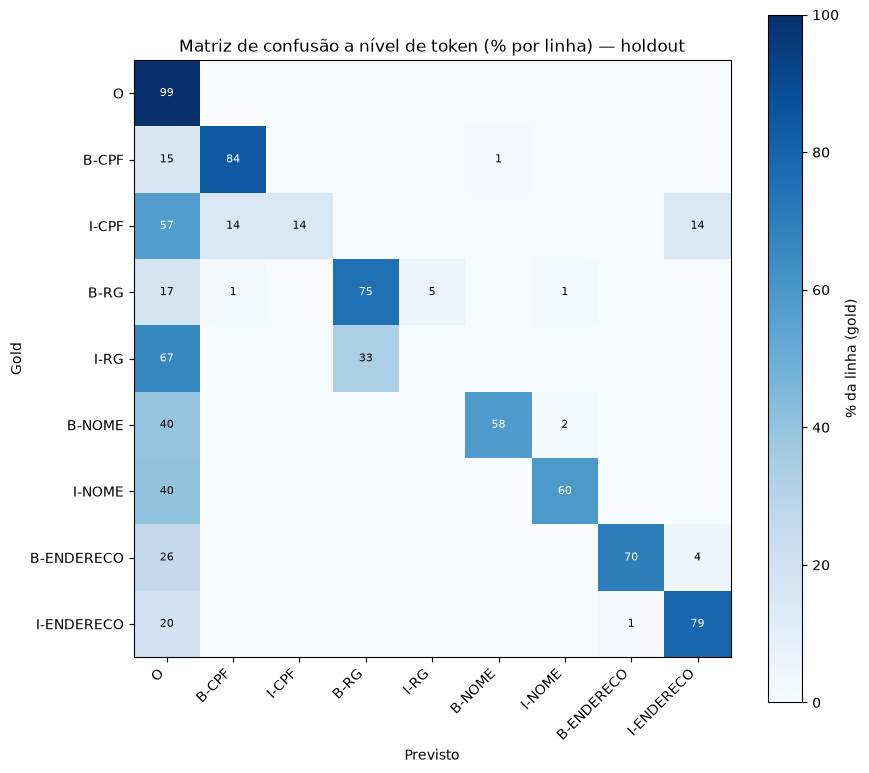

Contagem absoluta:


Previsto,O,B-CPF,I-CPF,B-RG,I-RG,B-NOME,I-NOME,B-ENDERECO,I-ENDERECO
Gold,,,,,,,,,
O,75473,13,3,5,4,68,193,12,133
B-CPF,34,193,0,0,0,2,0,0,0
I-CPF,4,1,1,0,0,0,0,0,1
B-RG,14,1,0,61,4,0,1,0,0
I-RG,4,0,0,2,0,0,0,0,0
B-NOME,289,0,0,0,0,426,16,0,0
I-NOME,870,0,0,0,0,5,1292,0,0
B-ENDERECO,19,0,0,0,0,0,0,51,3
I-ENDERECO,198,0,0,0,0,1,0,8,787


In [5]:
todas_labels_gold = []
todas_labels_previstas = []
for ex in exemplos_holdout:
    pred = predicoes_por_pagina[(ex["document_id"], ex["page"])]["tags_previstas"]
    todas_labels_gold.extend(ex["tags"])
    todas_labels_previstas.extend(pred)

matriz = pd.crosstab(
    pd.Series(todas_labels_gold, name="Gold"),
    pd.Series(todas_labels_previstas, name="Previsto"),
).reindex(index=LABEL_LIST, columns=LABEL_LIST, fill_value=0)

# Normaliza por linha (% do gold de cada label que foi para cada label previsto)
matriz_pct = matriz.div(matriz.sum(axis=1).replace(0, 1), axis=0) * 100

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(matriz_pct.values, cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(len(LABEL_LIST)))
ax.set_xticklabels(LABEL_LIST, rotation=45, ha="right")
ax.set_yticks(range(len(LABEL_LIST)))
ax.set_yticklabels(LABEL_LIST)
ax.set_xlabel("Previsto")
ax.set_ylabel("Gold")
ax.set_title("Matriz de confusão a nível de token (% por linha) — holdout")
for i in range(len(LABEL_LIST)):
    for j in range(len(LABEL_LIST)):
        valor = matriz_pct.values[i, j]
        if valor > 0.5:
            ax.text(j, i, f"{valor:.0f}", ha="center", va="center",
                     color="white" if valor > 50 else "black", fontsize=8)
plt.colorbar(im, ax=ax, label="% da linha (gold)")
plt.tight_layout()
plt.show()

print("Contagem absoluta:")
matriz

## 2. Classificação detalhada de cada erro (nível de entidade)

Para cada entidade do gabarito, classifica o resultado em:
- **TP**: encontrada com IoU >= limiar e tipo certo.
- **FN_perdida**: nenhuma previsão do mesmo tipo sobrepõe (o modelo simplesmente não viu nada ali).
- **FN_tipo_errado**: existe previsão sobrepondo a mesma região, mas de outro tipo (ex: previu ENDERECO onde era NOME).
- **FN_boundary**: existe previsão do tipo certo sobrepondo, mas IoU abaixo do limiar (limite/fronteira errado — pegou só parte do nome, ou incluiu texto demais).

Para cada previsão do modelo não usada por nenhum gold:
- **FP_espurio**: não há nenhuma entidade gold na região (o modelo "viu" uma entidade onde não tem nada).

In [6]:
erros = []  # cada item: dict com document_id, page, tipo_gold/tipo_previsto, categoria, texto_gold/texto_previsto, contexto

for ex in exemplos_holdout:
    doc_id, pagina = ex["document_id"], ex["page"]
    previstas = predicoes_por_pagina[(doc_id, pagina)]["entidades_previstas"]
    gold = gabarito_por_doc_pagina.get((doc_id, pagina), [])

    usadas_previstas = set()
    for g in gold:
        tipo_gold = g["type"]
        bbox_gold = bbox_externo(g.get("bbox") or [])

        # 1) tenta achar previsão do MESMO tipo com melhor IoU
        melhor_iou_mesmo_tipo, melhor_idx_mesmo_tipo = 0.0, None
        # 2) e também a melhor sobreposição (qualquer tipo), para diagnosticar tipo errado
        melhor_iou_qualquer, melhor_idx_qualquer, melhor_tipo_qualquer = 0.0, None, None
        for i, p in enumerate(previstas):
            if id(p) in usadas_previstas:
                continue
            score = iou(bbox_gold, bbox_externo(p["bbox"]))
            if score > melhor_iou_qualquer:
                melhor_iou_qualquer, melhor_idx_qualquer, melhor_tipo_qualquer = score, i, p["type"]
            if p["type"] == tipo_gold and score > melhor_iou_mesmo_tipo:
                melhor_iou_mesmo_tipo, melhor_idx_mesmo_tipo = score, i

        contexto_antes = g.get("context_before", "")
        contexto_depois = g.get("context_after", "")

        if melhor_idx_mesmo_tipo is not None and melhor_iou_mesmo_tipo >= IOU_MINIMO_MATCH:
            usadas_previstas.add(id(previstas[melhor_idx_mesmo_tipo]))
            categoria = "TP"
        elif melhor_idx_mesmo_tipo is not None and melhor_iou_mesmo_tipo > 0:
            categoria = "FN_boundary"
        elif melhor_idx_qualquer is not None and melhor_iou_qualquer >= IOU_MINIMO_MATCH:
            usadas_previstas.add(id(previstas[melhor_idx_qualquer]))
            categoria = "FN_tipo_errado"
        else:
            categoria = "FN_perdida"

        erros.append({
            "document_id": doc_id, "page": pagina, "categoria": categoria,
            "tipo_gold": tipo_gold, "texto_gold": g["text"],
            "tipo_previsto": (melhor_tipo_qualquer if categoria != "TP" else tipo_gold),
            "texto_previsto": (previstas[melhor_idx_qualquer]["text"] if melhor_idx_qualquer is not None else None),
            "iou": round(max(melhor_iou_mesmo_tipo, melhor_iou_qualquer), 3),
            "contexto_antes": contexto_antes, "contexto_depois": contexto_depois,
        })

    for p in previstas:
        if id(p) in usadas_previstas:
            continue
        antes, depois = contexto_em_torno(ex["tokens"], p["indices"])
        erros.append({
            "document_id": doc_id, "page": pagina, "categoria": "FP_espurio",
            "tipo_gold": None, "texto_gold": None,
            "tipo_previsto": p["type"], "texto_previsto": p["text"],
            "iou": 0.0, "contexto_antes": antes, "contexto_depois": depois,
        })

df_erros = pd.DataFrame(erros)
print(f"Total de itens avaliados (TP + erros): {len(df_erros)}")
df_erros["categoria"].value_counts()

Total de itens avaliados (TP + erros): 1256


categoria
TP                748
FN_perdida        365
FP_espurio        118
FN_boundary        22
FN_tipo_errado      3
Name: count, dtype: int64

In [7]:
print("=== Categoria de erro por TIPO (linhas = tipo do gold, exceto FP_espurio que não tem gold) ===\n")
tabela = pd.crosstab(df_erros["tipo_gold"].fillna("(sem gold — FP)"), df_erros["categoria"])
cols_ordem = [c for c in ["TP", "FN_boundary", "FN_tipo_errado", "FN_perdida", "FP_espurio"] if c in tabela.columns]
tabela = tabela[cols_ordem]
print(tabela)

print("\n=== FP_espurio por tipo previsto (o que o modelo 'viu' sem ter nada de verdade) ===")
print(df_erros[df_erros["categoria"] == "FP_espurio"]["tipo_previsto"].value_counts())

=== Categoria de erro por TIPO (linhas = tipo do gold, exceto FP_espurio que não tem gold) ===

categoria         TP  FN_boundary  FN_tipo_errado  FN_perdida  FP_espurio
tipo_gold                                                                
(sem gold — FP)    0            0               0           0         118
CPF              193            1               1          35           0
ENDERECO          60            1               0          17           0
NOME             431           17               0         301           0
RG                64            3               2          12           0

=== FP_espurio por tipo previsto (o que o modelo 'viu' sem ter nada de verdade) ===
tipo_previsto
NOME        84
ENDERECO    15
CPF         14
RG           5
Name: count, dtype: int64


## 3. Amostras de erro para leitura manual (tipo em foco: `TIPO_FOCO`)

Mostra o texto + contexto de exemplos reais de cada categoria de erro, para inspeção qualitativa.

In [8]:
for categoria in ["FN_perdida", "FN_boundary", "FN_tipo_errado"]:
    subset = df_erros[(df_erros["categoria"] == categoria) & (df_erros["tipo_gold"] == TIPO_FOCO)]
    print(f"\n{'=' * 90}\n{categoria} — {TIPO_FOCO} ({len(subset)} ocorrência(s), mostrando até {N_AMOSTRAS_POR_CATEGORIA})\n{'=' * 90}")
    for _, row in subset.head(N_AMOSTRAS_POR_CATEGORIA).iterrows():
        print(f"  [{row['document_id']} p{row['page']}] gold=\"{row['texto_gold']}\" (iou={row['iou']})")
        print(f"    contexto: ...{row['contexto_antes']} >>>{row['texto_gold']}<<< {row['contexto_depois']}...")
        if row["texto_previsto"]:
            print(f"    modelo previu ({row['tipo_previsto']}): \"{row['texto_previsto']}\"")
        print()

subset_fp = df_erros[(df_erros["categoria"] == "FP_espurio") & (df_erros["tipo_previsto"] == TIPO_FOCO)]
print(f"\n{'=' * 90}\nFP_espurio — {TIPO_FOCO} ({len(subset_fp)} ocorrência(s), mostrando até {N_AMOSTRAS_POR_CATEGORIA})\n{'=' * 90}")
for _, row in subset_fp.head(N_AMOSTRAS_POR_CATEGORIA).iterrows():
    print(f"  [{row['document_id']} p{row['page']}] modelo previu \"{row['texto_previsto']}\" onde não havia entidade")
    print(f"    contexto: ...{row['contexto_antes']} >>>{row['texto_previsto']}<<< {row['contexto_depois']}...\n")


FN_perdida — NOME (301 ocorrência(s), mostrando até 15)
  [cm1iasv3k0031dhqdfn4663iw-Alteração 11 - MINAS CAL.pdf p1] gold="Marinely de Paula Bomfim" (iou=0.0)
    contexto: ...assinada em 11/03/2021 por >>>Marinely de Paula Bomfim<<< - Secretária-Geral....
    modelo previu (nan): "nan"

  [cm1iasv3k0031dhqdfn4663iw-Alteração 11 - MINAS CAL.pdf p1] gold="MARINELY DE PAULA BOMFIM" (iou=0.0)
    contexto: ...assinada em 11/03/2021 por >>>MARINELY DE PAULA BOMFIM<<< SECRETÁRIA GERAL...
    modelo previu (nan): "nan"

  [cm1iasv3k0031dhqdfn4663iw-Alteração 11 - MINAS CAL.pdf p3] gold="SÉRGIO LÚCIO SOARES" (iou=0.0)
    contexto: ...34.590-110; >>>SÉRGIO LÚCIO SOARES<<< brasileiro, divorciado, nascido aos...
    modelo previu (nan): "nan"

  [cm1iasv3k0031dhqdfn4663iw-Alteração 11 - MINAS CAL.pdf p3] gold="Marinely de Paula Bomfim" (iou=0.0)
    contexto: ...assinada em 11/03/2021 por >>>Marinely de Paula Bomfim<<< - Secretária-Geral....
    modelo previu (nan): "nan"

  [cm1iasv3k0031dhq

## 4. Ranking dos documentos com mais erros

In [9]:
df_erros_reais = df_erros[df_erros["categoria"] != "TP"]
ranking = df_erros_reais.groupby("document_id").size().sort_values(ascending=False)
n_gold_por_doc = df_erros[df_erros["tipo_gold"].notna()].groupby("document_id").size()

print(f"{'Documento':<70}{'Erros':<8}{'Total gold':<12}{'% erro'}")
print("-" * 100)
for doc_id, n_erros in ranking.head(20).items():
    n_gold = n_gold_por_doc.get(doc_id, 0)
    pct = 100 * n_erros / n_gold if n_gold else float("nan")
    print(f"{doc_id[:68]:<70}{n_erros:<8}{n_gold:<12}{pct:.1f}%")

Documento                                                             Erros   Total gold  % erro
----------------------------------------------------------------------------------------------------
cmhjmy4i1001q01n3fsat4dmg-2aalteracaocontratualregistradametalferpdf  66      128         51.6%
cm37fqf0n0006hnqd6jjm3xrc-POZOMINAS - TRANSFORMAÇÃO DE S.A. PARA LTD  62      106         58.5%
cmm0yp5wb005501nx24wq314w-contratof11pdf                              37      85          43.5%
cm1qczv5u0008v6qd426f9fgv-CORTEC - Alteração Consolidada290720.pdf    32      63          50.8%
cm1iasv3k0031dhqdfn4663iw-Alteração 11 - MINAS CAL.pdf                26      42          61.9%
cmkwujf49000201nxemxeaf9o-ltimaalteraocontratuallibpdf                25      71          35.2%
cmod12h77007m01nwb5eldybv-estatutoconsolidado2015pdf                  23      33          69.7%
cm3376wbs002xzaqd1p4r02h0-15 Alteração Contratual.pdf                 22      23          95.7%
cmfczvaui000b01mj0pm1byub-alteraca

## 5. Salva o relatório completo de erros (CSV) para inspeção fora do notebook

In [10]:
caminho_csv = PASTA_SAIDA_METRICAS / f"erros_holdout_{cenario_escolhido['nome']}.csv"
df_erros.to_csv(caminho_csv, index=False, encoding="utf-8-sig")
print(f"Relatório completo salvo em: {caminho_csv}")
print(f"({len(df_erros)} linhas — abra no Excel/Sheets para filtrar por categoria/tipo)")

Relatório completo salvo em: d:\Arquivos\ProjetosPython\BFC\LocalScanDocument_v3\models\bertimbau-pii-v1-cenarios-sem-sinteticos\metricas_holdout\erros_holdout_c08_warmup.csv
(1256 linhas — abra no Excel/Sheets para filtrar por categoria/tipo)


## 6. Pós-processamento heurístico: ganho de regex de assinatura digital + propagação de texto idêntico

Duas correções em `scripts/pos_processamento_ner.py` (ver `anotacoes/anotacoes.txt` 2026-09-11):
1. **Regex para o padrão `ASSINADO DIGITALMENTE POR: <CPF>-<NOME>`** — o nome sai fundido com o CPF no mesmo token (quebra a tokenização de subpalavras do BERT), então o modelo nunca aprende a separar isso.
2. **Propagação de entidade por texto idêntico** — quando o mesmo texto exato de uma entidade já detectada em algum lugar do documento aparece de novo (ex.: nome de uma autoridade repetido em rodapé de certificação em todas as páginas) sem ter sido marcado, propaga a marcação para essa outra ocorrência dentro do mesmo documento.

(A extensão heurística de boundary de NOME testada anteriormente piorou o resultado — ver anotacoes.txt — e não é usada aqui.)

In [11]:
import sys

sys.path.insert(0, str(RAIZ / "scripts"))
from pos_processamento_ner import extrair_nome_assinatura_digital, propagar_entidades_por_texto_identico


def avaliar_com_pos_processamento(exemplos: list, aplicar_regex: bool, aplicar_propagacao: bool) -> dict:
    contadores = {t: {"tp": 0, "fp": 0, "fn": 0} for t in TIPOS}

    exemplos_por_doc = defaultdict(list)
    for ex in exemplos:
        exemplos_por_doc[ex["document_id"]].append(ex)

    for doc_id, exs in exemplos_por_doc.items():
        previstas_por_pagina = {}
        entidades_documento = []
        for ex in exs:
            previstas = [dict(p) for p in predicoes_por_pagina[(doc_id, ex["page"])]["entidades_previstas"]]

            if aplicar_regex:
                extras = extrair_nome_assinatura_digital(ex["tokens"], ex["tokens_bbox"])
                for extra in extras:
                    bbox_extra = bbox_externo(extra["bbox"])
                    ja_coberto = any(
                        p["type"] == "NOME" and iou(bbox_extra, bbox_externo(p["bbox"])) > 0.1
                        for p in previstas
                    )
                    if not ja_coberto:
                        previstas.append(extra)

            for p in previstas:
                p["page"] = ex["page"]
            previstas_por_pagina[ex["page"]] = previstas
            entidades_documento.extend(previstas)

        if aplicar_propagacao:
            paginas_doc = [
                {"page": ex["page"], "tokens": [{"text": t, "bbox": b} for t, b in zip(ex["tokens"], ex["tokens_bbox"])]}
                for ex in exs
            ]
            # `propagar_entidades_por_texto_identico` agora devolve a lista COMPLETA já
            # corrigida (substitui, não concatena) -- mudança de contrato 2026-09-15: quando
            # uma entidade existente cobre só uma PARTE do span canônico repetido em outra
            # posição/página (ex.: modelo previu só "302" onde o texto completo do carimbo é
            # "AV. BIAS FORTES, 932 CONJ. 302 [...]"), ela é substituída pelo span completo,
            # priorizando consistência de marcação entre páginas idênticas do mesmo documento.
            entidades_documento = propagar_entidades_por_texto_identico(
                entidades_documento, paginas_doc, tipos_propagaveis=tuple(TIPOS)
            )
            previstas_por_pagina = defaultdict(list)
            for p in entidades_documento:
                previstas_por_pagina[p["page"]].append(p)

        for ex in exs:
            previstas = previstas_por_pagina.get(ex["page"], [])
            gold = gabarito_por_doc_pagina.get((doc_id, ex["page"]), [])
            previstas_por_tipo = {}
            for p in previstas:
                previstas_por_tipo.setdefault(p["type"], []).append(p)

            usadas = set()
            for g in gold:
                tipo = g["type"]
                candidatos = previstas_por_tipo.get(tipo, [])
                bbox_gold = bbox_externo(g.get("bbox") or [])
                melhor_iou, melhor_idx = 0.0, None
                for i, p in enumerate(candidatos):
                    if id(p) in usadas:
                        continue
                    score = iou(bbox_gold, bbox_externo(p["bbox"]))
                    if score > melhor_iou:
                        melhor_iou, melhor_idx = score, i
                if melhor_idx is not None and melhor_iou >= IOU_MINIMO_MATCH:
                    usadas.add(id(candidatos[melhor_idx]))
                    contadores[tipo]["tp"] += 1
                else:
                    contadores[tipo]["fn"] += 1

            for tipo, candidatos in previstas_por_tipo.items():
                for p in candidatos:
                    if id(p) not in usadas:
                        contadores.setdefault(tipo, {"tp": 0, "fp": 0, "fn": 0})
                        contadores[tipo]["fp"] += 1
    return contadores


def imprimir_pos_proc(titulo: str, contadores: dict) -> dict:
    print(f"\n=== {titulo} ===")
    print(f"{'Tipo':<10}{'TP':<6}{'FP':<6}{'FN':<6}{'Precision':<12}{'Recall':<10}{'F1':<8}")
    tp_g = fp_g = fn_g = 0
    for tipo in TIPOS:
        c = contadores[tipo]
        tp, fp, fn = c["tp"], c["fp"], c["fn"]
        tp_g += tp; fp_g += fp; fn_g += fn
        precision = tp / (tp + fp) if (tp + fp) else 0.0
        recall = tp / (tp + fn) if (tp + fn) else 0.0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
        print(f"{tipo:<10}{tp:<6}{fp:<6}{fn:<6}{precision:<12.3f}{recall:<10.3f}{f1:<8.3f}")
    precision_g = tp_g / (tp_g + fp_g) if (tp_g + fp_g) else 0.0
    recall_g = tp_g / (tp_g + fn_g) if (tp_g + fn_g) else 0.0
    f1_g = 2 * precision_g * recall_g / (precision_g + recall_g) if (precision_g + recall_g) else 0.0
    print(f"{'GERAL':<10}{tp_g:<6}{fp_g:<6}{fn_g:<6}{precision_g:<12.3f}{recall_g:<10.3f}{f1_g:<8.3f}")
    return {"tp": tp_g, "fp": fp_g, "fn": fn_g, "precision": precision_g, "recall": recall_g, "f1": f1_g}


r_base = imprimir_pos_proc("BASE (sem pós-processamento)", avaliar_com_pos_processamento(exemplos_holdout, False, False))
r_regex = imprimir_pos_proc("+ regex assinatura digital", avaliar_com_pos_processamento(exemplos_holdout, True, False))
r_regex_prop = imprimir_pos_proc("+ regex + propagação de texto idêntico", avaliar_com_pos_processamento(exemplos_holdout, True, True))

print(f"\nF1 GERAL — base: {r_base['f1']:.3f} | +regex: {r_regex['f1']:.3f} | +regex+propagação: {r_regex_prop['f1']:.3f}")


=== BASE (sem pós-processamento) ===
Tipo      TP    FP    FN    Precision   Recall    F1      
CPF       193   15    37    0.928       0.839     0.881   
RG        64    5     17    0.928       0.790     0.853   
NOME      432   85    317   0.836       0.577     0.682   
ENDERECO  60    15    18    0.800       0.769     0.784   
GERAL     749   120   389   0.862       0.658     0.746   

=== + regex assinatura digital ===
Tipo      TP    FP    FN    Precision   Recall    F1      
CPF       193   15    37    0.928       0.839     0.881   
RG        64    5     17    0.928       0.790     0.853   
NOME      433   85    316   0.836       0.578     0.684   
ENDERECO  60    15    18    0.800       0.769     0.784   
GERAL     750   120   388   0.862       0.659     0.747   

=== + regex + propagação de texto idêntico ===
Tipo      TP    FP    FN    Precision   Recall    F1      
CPF       216   16    14    0.931       0.939     0.935   
RG        66    6     15    0.917       0.815     0.

## 7. Visualização: página do PDF com as caixas sobrepostas

Verde = TP (acertou), vermelho = gold perdido (FN), laranja tracejado = previsão sem gold correspondente (FP). Reflete o modelo puro (sem o pós-processamento da seção 6). Preencha `DOC_ID_VISUALIZAR` e `PAGINA_VISUALIZAR` com um documento do ranking acima (ou de `df_erros`) para inspecionar visualmente.

In [ ]:
import fitz  # PyMuPDF

DOC_ID_VISUALIZAR = ranking.index[0] if len(ranking) else None  # documento com mais erros, por padrão
PAGINA_VISUALIZAR = 1

def localizar_pdf_original(document_id: str) -> Path:
    candidato = PASTA_ARQUIVOS_HOLDOUT / document_id
    if candidato.exists():
        return candidato
    achados = list(PASTA_ARQUIVOS_HOLDOUT.glob(f"{Path(document_id).stem}*"))
    if achados:
        return achados[0]
    raise FileNotFoundError(f"PDF original não encontrado para {document_id} em {PASTA_ARQUIVOS_HOLDOUT}")


if DOC_ID_VISUALIZAR:
    caminho_pdf = localizar_pdf_original(DOC_ID_VISUALIZAR)
    doc = fitz.open(caminho_pdf)
    pagina_pdf = doc[PAGINA_VISUALIZAR - 1]

    previstas = predicoes_por_pagina.get((DOC_ID_VISUALIZAR, PAGINA_VISUALIZAR), {}).get("entidades_previstas", [])
    gold = gabarito_por_doc_pagina.get((DOC_ID_VISUALIZAR, PAGINA_VISUALIZAR), [])

    usadas = set()
    for g in gold:
        bbox_gold = bbox_externo(g.get("bbox") or [])
        melhor_iou, melhor_idx = 0.0, None
        for i, p in enumerate(previstas):
            if id(p) in usadas or p["type"] != g["type"]:
                continue
            score = iou(bbox_gold, bbox_externo(p["bbox"]))
            if score > melhor_iou:
                melhor_iou, melhor_idx = score, i
        if melhor_idx is not None and melhor_iou >= IOU_MINIMO_MATCH:
            usadas.add(id(previstas[melhor_idx]))
            cor = (0, 0.6, 0)  # verde = TP
        else:
            cor = (0.8, 0, 0)  # vermelho = FN
        # Desenha CADA retângulo por linha de g["bbox"] separadamente -- usar
        # bbox_externo() (um retângulo único cobrindo todas as linhas) faz o desenho
        # "vazar" para a esquerda quando uma entidade quebra linha e a 2ª linha começa
        # mais à esquerda que a 1ª (comum: 1ª linha começa no meio da frase, 2ª linha
        # começa na margem) -- cobre visualmente texto que não é da entidade (achado
        # 2026-09-15, caso MINAS CAL/endereço do Sérgio). bbox_externo() continua sendo
        # usado só para o cálculo de IoU (matching), que não tem esse problema.
        for retangulo in (g.get("bbox") or []):
            pagina_pdf.draw_rect(fitz.Rect(*retangulo), color=cor, width=1.5)

    for i, p in enumerate(previstas):
        if id(p) in usadas:
            continue
        for retangulo in (p.get("bbox") or []):
            pagina_pdf.draw_rect(fitz.Rect(*retangulo), color=(1, 0.55, 0), width=1.5, dashes="[3] 0")  # laranja tracejado = FP

    pix = pagina_pdf.get_pixmap(dpi=150)
    img_bytes = pix.tobytes("png")
    doc.close()

    from io import BytesIO
    from PIL import Image
    plt.figure(figsize=(11, 15))
    plt.imshow(Image.open(BytesIO(img_bytes)))
    plt.axis("off")
    plt.title(f"{DOC_ID_VISUALIZAR} — página {PAGINA_VISUALIZAR}\nverde=TP  vermelho=FN(perdido)  laranja tracejado=FP")
    plt.tight_layout()
    plt.show()
else:
    print("Nenhum documento com erro encontrado (ranking vazio) — nada para visualizar.")